## Ground truths

In [1]:
import torch
import numpy as np
import matplotlib.pyplot as plt

def box_sdf(p: torch.Tensor, b: torch.Tensor) -> torch.Tensor:
    b = b.to(p.device)
    q = p.abs() - b
    return q.clamp(min=0.0).norm(dim=-1) + q.amax(dim=-1).clamp(max=0.0)

def torus_sdf(p: torch.Tensor, t: torch.Tensor) -> torch.Tensor:
    t = t.to(p.device)
    q = torch.stack([
        p[..., [0, 2]].norm(dim=-1) - t[0],  # length(p.xz) - t.x
        p[..., 1],                            # p.y
    ], dim=-1)
    return q.norm(dim=-1) - t[1]

## Visualization

### Slice visualization

In [2]:
import matplotlib.pyplot as plt
import numpy as np

def visualize_comparison(models=None, sdf_funcs=None, grid_res=200):

    device = torch.device('cuda:0' if torch.cuda.is_available() else 'cpu')
    eps = 1e-5
    gridx = torch.linspace(-2 + eps, 2 - eps, grid_res)
    gridy = torch.linspace(-2 + eps, 2 - eps, grid_res)
    X_mesh, Y_mesh = torch.meshgrid(gridx, gridy, indexing='ij')
    Z_zero = torch.zeros_like(X_mesh.flatten())  # coupe z=0
    input_pts = torch.stack([X_mesh.flatten(), Y_mesh.flatten(), Z_zero], dim=1).to(device)
    xn = X_mesh.cpu().numpy()
    yn = Y_mesh.cpu().numpy()
    spacing = (gridx[1] - gridx[0]).item()

    models    = models    or []
    sdf_funcs = sdf_funcs or []

    def compute_Z(Z_flat):
        Z = Z_flat.reshape(grid_res, grid_res).cpu().numpy()
        dZdx, dZdy = np.gradient(Z, spacing)
        mag = np.sqrt(dZdx**2 + dZdy**2)
        return Z, mag

    def plot_row(ax_sdf, ax_grad, Z, mag, title):
        max_abs = np.max(np.abs(Z))
        cp = ax_sdf.contourf(xn, yn, Z, levels=100, cmap='RdBu',
                              vmin=-max_abs, vmax=max_abs)
        ax_sdf.contour(xn, yn, Z, levels=[0], colors='white', linewidths=2)
        ax_sdf.set_title(f"{title} — SDF (z=0)", fontweight='bold')
        ax_sdf.set_aspect('equal')
        ax_sdf.set_xlim(-2, 2)
        ax_sdf.set_ylim(-2, 2)
        plt.colorbar(cp, ax=ax_sdf, label='Distance')

        im = ax_grad.imshow(mag.T, extent=[-2, 2, -2, 2],
                             origin='lower', cmap='viridis', vmin=0)
        ax_grad.set_title(f"{title} — ‖∇f‖ (z=0)", fontweight='bold')
        ax_grad.set_aspect('equal')
        plt.colorbar(im, ax=ax_grad, label='Magnitude')

    n_rows = len(models) + len(sdf_funcs)
    assert n_rows > 0, "Fournir au moins un modèle ou une GT."
    fig, axes = plt.subplots(n_rows, 2, figsize=(12, 5 * n_rows),
                              constrained_layout=True)
    if n_rows == 1:
        axes = axes[np.newaxis, :]

    row = 0
    for model, name in models:
        model.eval()
        with torch.no_grad():
            Z_flat = model(input_pts)
        Z, mag = compute_Z(Z_flat)
        plot_row(axes[row, 0], axes[row, 1], Z, mag, name)
        row += 1

    for sdf_func, name in sdf_funcs:
        with torch.no_grad():
            Z_flat = sdf_func(input_pts)
        Z, mag = compute_Z(Z_flat)
        plot_row(axes[row, 0], axes[row, 1], Z, mag, f"GT — {name}")
        row += 1

    plt.suptitle("Comparaison des modèles (coupe z=0)", fontsize=16, fontweight='bold')
    plt.show()

### Zero level set extraction

In [3]:
from kaolin.ops.conversions import FlexiCubes
import plotly.graph_objects as go


def build_grid(domain, grid_res, device):
    coords = torch.linspace(domain[0], domain[1], grid_res, device=device)
    X, Y, Z = torch.meshgrid(coords, coords, coords, indexing='ij')
    return torch.stack([X.flatten(), Y.flatten(), Z.flatten()], dim=1)


def eval_in_batches(eval_fn, pts, batch_size=None):
    if batch_size is None:
        return eval_fn(pts).view(-1)
    out = torch.empty(pts.shape[0], device=pts.device)
    for i in range(0, pts.shape[0], batch_size):
        chunk = eval_fn(pts[i:i + batch_size])
        out[i:i + chunk.shape[0]] = chunk.view(-1)
    return out


def sample_sdf_model(model, domain=[-2, 2], grid_res=200, batch_size=200_000):
    device = next(model.parameters()).device
    input_pts = build_grid(domain, grid_res, device)
    model.eval()
    with torch.no_grad():
        sampled_sdf = eval_in_batches(model, input_pts, batch_size)
    return input_pts, sampled_sdf  # input_pts restauré : sinon impossible d'exploiter les valeurs ailleurs (slices, erreur ponctuelle, etc.)


def sample_sdf_GT(sdf_func, domain=[-2, 2], grid_res=200, device='cpu', **sdf_kwargs):
    input_pts = build_grid(domain, grid_res, device)
    eval_fn = lambda pts: sdf_func(pts, **sdf_kwargs)
    sampled_sdf = eval_in_batches(eval_fn, input_pts)
    return input_pts, sampled_sdf


def _affine_map(pts, src_lo, src_hi, domain):
    t = (pts - src_lo) / (src_hi - src_lo)
    return t * (domain[1] - domain[0]) + domain[0]


def simple_extract(sdf, domain=[-2, 2], resolution=64, device='cpu', batch_size=200_000):
    is_model = isinstance(sdf, torch.nn.Module)
    if is_model:
        device = next(sdf.parameters()).device
        sdf.eval()

    fc = FlexiCubes(device)
    fc_res = resolution - 1
    x_nx3, cube_fx8 = fc.construct_voxel_grid(fc_res)
    x_nx3 = x_nx3.to(device)

    lo, hi = x_nx3.amin(dim=0, keepdim=True), x_nx3.amax(dim=0, keepdim=True)
    query_pts = _affine_map(x_nx3, lo, hi, domain)

    if is_model:
        with torch.no_grad():
            sampled_sdf = eval_in_batches(sdf, query_pts, batch_size)
    else:
        sampled_sdf = eval_in_batches(sdf, query_pts)

    verts, faces, _ = fc(x_nx3, sampled_sdf, cube_fx8, fc_res)
    verts = _affine_map(verts, lo, hi, domain)

    faces_np = faces.detach().cpu().numpy().astype(np.int32)
    verts_np = verts.detach().cpu().numpy().astype(np.float32)
    return verts_np, faces_np


def visualize_zero_set(sdf, domain=[-2, 2], resolution=64, device='cpu', batch_size=200_000, title=None):
    verts, faces = simple_extract(sdf, domain=domain, resolution=resolution, device=device, batch_size=batch_size)
    if title is None:
        title = f"{'Model' if isinstance(sdf, torch.nn.Module) else 'GT'} SDF zero-set (res={resolution})"

    fig = go.Figure(data=[go.Mesh3d(
        x=verts[:, 0], y=verts[:, 1], z=verts[:, 2],
        i=faces[:, 0], j=faces[:, 1], k=faces[:, 2],
        color='lightblue',
        opacity=1.0,
    )])
    fig.update_layout(
        title=title,
        scene=dict(
            xaxis=dict(title='X', range=domain),
            yaxis=dict(title='Y', range=domain),
            zaxis=dict(title='Z', range=domain),
            aspectmode='cube'
        ),
        margin=dict(l=0, r=0, t=40, b=0),
    )
    fig.show()
    return verts,faces

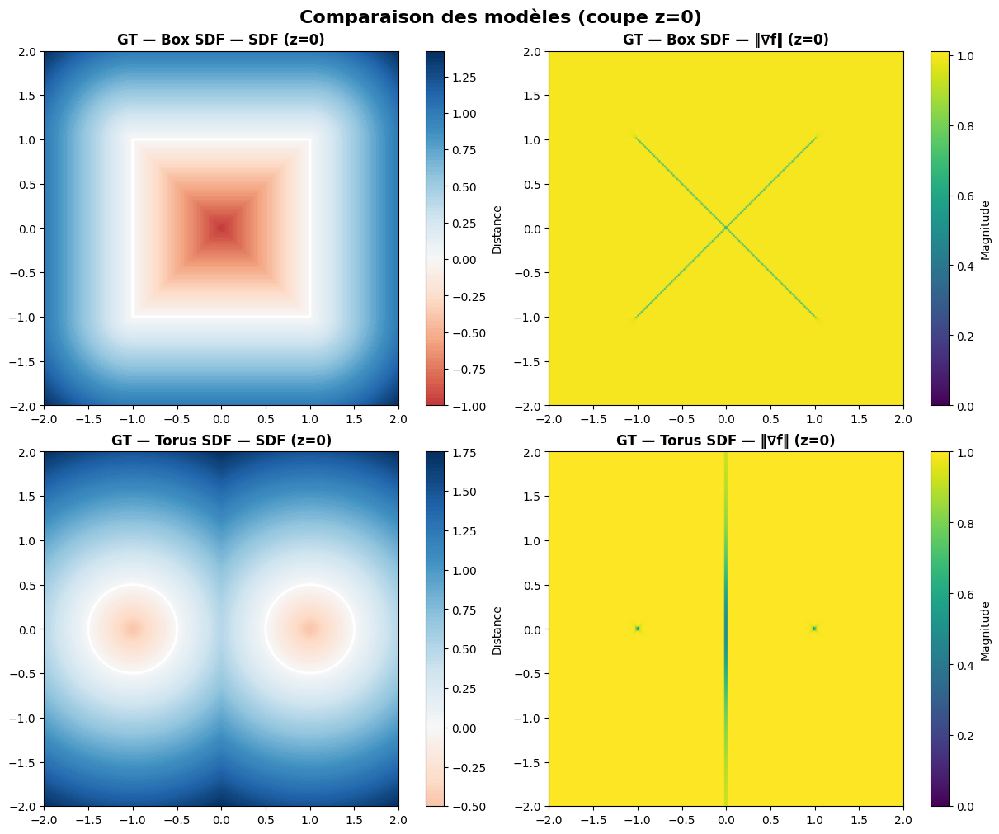

In [233]:
device = torch.device('cuda:0' if torch.cuda.is_available() else 'cpu')
b = torch.tensor([1.0, 1.0, 1.0])
t = torch.tensor([1.0, 0.5])
visualize_comparison(models=None, sdf_funcs=[(lambda p: box_sdf(p, b), "Box SDF"), (lambda p: torus_sdf(p, t), "Torus SDF")], grid_res=200)
visualize_zero_set(lambda p: box_sdf(p, b), domain=[-2, 2], resolution=64, device=device)
visualize_zero_set(lambda p: torus_sdf(p, t), domain=[-2, 2], resolution=64, device=device)

## Reseau SLL 3D

In [4]:
import torch
import torch.nn as nn
import torch.nn.functional as F


class SLLLayer(nn.Module):
    def __init__(self, k, scale=1.0):
        super().__init__()
        self.scale = scale
        self.W = nn.Parameter(torch.randn(k, k) * (1.0 / k**0.5))
        self.b = nn.Parameter(torch.zeros(k))
        self.q = nn.Parameter(torch.zeros(k))

    def forward(self, x):
        WtW = self.W.T @ self.W
        q = self.q
        T = torch.abs(WtW * torch.exp(q[None, :] - q[:, None])).sum(dim=1)
        T_inv = 1.0 / (T + 1e-8)
        h = torch.relu(x @ self.W + self.b)
        return (x - 2.0 * (h * T_inv) @ self.W.T) * self.scale


class LipschitzSDF(nn.Module):
    def __init__(self, k=128, n_layers=20):
        super().__init__()
        self.k = k
        self.sll = nn.Sequential(*[SLLLayer(k) for _ in range(n_layers)])
        self.w_out = nn.Parameter(torch.randn(k) / k**0.5)
        self.b_out = nn.Parameter(torch.zeros(1))

    def forward(self, x):
        # zero-pad l'entrée (n=2) vers la dimension k
        x = torch.nn.functional.pad(x, (0, self.k - x.shape[-1]))
        x = self.sll(x)
        # 1-Lipschitz : w^T x / ||w||_2 + b
        return (x @ self.w_out) / self.w_out.norm() + self.b_out

class LossHKR:
    def __init__(self, margin: float, lbda: float):
        self.margin = margin
        self.lbda   = lbda

    def __call__(self, y: torch.Tensor) -> torch.Tensor:
        return F.relu(self.margin - y) + (1.0 / self.lbda) * torch.mean(-y)


In [5]:
def train_Lipschitz_3D(model, sdf_func, nb_samples, lr, nb_epochs,
                   m=0.01, lambda_schedule=None, parallel=False, domain=[-2, 2]):
    device = torch.device('cuda:0' if torch.cuda.is_available() else 'cpu')
    if parallel and torch.cuda.device_count() > 1:
        print(f"Using {torch.cuda.device_count()} GPUs for training.")
        model = nn.DataParallel(model)
    model = model.to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)

    if lambda_schedule is None:
        lambda_schedule = {i : 10*(i-1) for i in range(nb_epochs//100)}

    loss_fn = LossHKR(margin=m, lbda=1.0)
    history = []

    for epoch in range(nb_epochs):
        if epoch in lambda_schedule:
            loss_fn.lbda = lambda_schedule[epoch]
            print(f"  → λ = {loss_fn.lbda}")

        x = (torch.rand(nb_samples, 3, device=device) * (domain[1] - domain[0])) + domain[0]

        with torch.no_grad():
            sdf_vals = sdf_func(x)

        y = torch.where(sdf_vals >= 0,
                         torch.ones_like(sdf_vals),
                         -torch.ones_like(sdf_vals))

        pred = model(x).squeeze()
        loss = loss_fn(y * pred).mean()

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()


        history.append(loss.item())
        if epoch % (nb_epochs // 10) == 0:
            print(f"Epoch {epoch:5d} | loss={loss.item():.5f}")

    return model, history

## Reseau Mlp eikonal

In [6]:
import torch
import torch.nn as nn


"""
This network class is from https://github.com/mintpancake/2d-sdf-net and was slightly modified"""


# The structure proposed in DeepSDF paper
class SDFNet(nn.Module):
    def __init__(self, dropout_prob=0.2, inDim=3):
        super(SDFNet, self).__init__()
        self.fc_stack_1 = nn.Sequential(
            nn.utils.weight_norm(nn.Linear(inDim, 512)),
            nn.ReLU(),
            nn.Dropout(p=dropout_prob),
            nn.utils.weight_norm(nn.Linear(512, 512)),
            nn.ReLU(),
            nn.Dropout(p=dropout_prob),
            nn.utils.weight_norm(nn.Linear(512, 512)),
            nn.ReLU(),
            nn.Dropout(p=dropout_prob),
            nn.utils.weight_norm(nn.Linear(512, 512 - inDim)),  # 510 = 512 - 2
            nn.ReLU(),
            nn.Dropout(p=dropout_prob)
        )
        self.fc_stack_2 = nn.Sequential(
            nn.utils.weight_norm(nn.Linear(512, 512)),
            nn.ReLU(),
            nn.Dropout(p=dropout_prob),
            nn.utils.weight_norm(nn.Linear(512, 512)),
            nn.ReLU(),
            nn.Dropout(p=dropout_prob),
            nn.utils.weight_norm(nn.Linear(512, 512)),
            nn.ReLU(),
            nn.Dropout(p=dropout_prob),
            nn.utils.weight_norm(nn.Linear(512, 1))
        )
        self.th = nn.Tanh()

    def forward(self, x):
        skip_out = self.fc_stack_1(x)
        skip_in = torch.cat([skip_out, x], 1)
        return self.fc_stack_2(skip_in)

In [7]:
def train_eikonal(model, sdf_func, nb_samples, lr, nb_epochs, loss_type='mse', eik_weight=0.1):
    model = model.to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    criterion = nn.MSELoss() if loss_type == 'mse' else nn.L1Loss()

    for epoch in range(nb_epochs):
        x = (torch.rand(nb_samples, 3, device=device) * 4) - 2
        x.requires_grad_(True)

        target = sdf_func(x)

        out = model(x).squeeze()
        loss_dist = criterion(out, target)

        grads = torch.autograd.grad(out.sum(), x, create_graph=True)[0]
        loss_eikonal = ((grads.norm(dim=-1) - 1.0) ** 2).mean()

        total_loss = loss_dist + eik_weight * loss_eikonal
        optimizer.zero_grad()
        total_loss.backward()
        optimizer.step()

        if epoch % 500 == 0:
            print(f"Epoch {epoch:5d} | total={total_loss.item():.5f} | dist={loss_dist.item():.5f} | eik={loss_eikonal.item():.5f}")

    return model

## Training

In [62]:
b = torch.tensor([1.0, 1.0, 1.0])
cube_model, cube_history = train_Lipschitz_3D(
    LipschitzSDF(k=128, n_layers=20),
    sdf_func=lambda p: box_sdf(p, b),
    nb_samples=100_000,
    lr=1e-3,
    nb_epochs=8000,
    domain=[-2, 2],
    lambda_schedule={
        0:    10,
        500:  30,
        1000: 60,
        2000: 100,
    },
    m=0.01,
    parallel=True
)

Using 2 GPUs for training.
  → λ = 10
Epoch     0 | loss=0.02437
  → λ = 30
Epoch   800 | loss=-0.02264
  → λ = 60
Epoch  1600 | loss=-0.01095
  → λ = 100
Epoch  2400 | loss=-0.00644
Epoch  3200 | loss=-0.00652
Epoch  4000 | loss=-0.00649
Epoch  4800 | loss=-0.00649
Epoch  5600 | loss=-0.00651
Epoch  6400 | loss=-0.00656
Epoch  7200 | loss=-0.00657


In [ ]:
t = torch.tensor([1.0, 0.5])
torus_model, torus_history = train_Lipschitz_3D(
    LipschitzSDF(k=128, n_layers=20),
    sdf_func=lambda p: torus_sdf(p, t),
    nb_samples=100_000,
    lr=1e-3,
    nb_epochs=8000,
    domain=[-2, 2],
    lambda_schedule={
        0:    10,
        500:  30,
        1000: 60,
        2000: 100,
    },
    parallel=True
)

In [ ]:
b = torch.tensor([1.0, 1.0, 1.0])
cube_eik_model = train_eikonal(
    SDFNet(dropout_prob=0.2, inDim=3),
    sdf_func=lambda p: box_sdf(p, b),
    nb_samples=100_000,
    lr=1e-3,
    nb_epochs=8000,
    loss_type='mse',
    eik_weight=0.1
)

Epoch     0 | total=0.61180 | dist=0.51275 | eik=0.99051
Epoch   500 | total=0.00678 | dist=0.00451 | eik=0.02269
Epoch  1000 | total=0.00524 | dist=0.00325 | eik=0.01988
Epoch  1500 | total=0.00470 | dist=0.00278 | eik=0.01921
Epoch  2000 | total=0.00431 | dist=0.00240 | eik=0.01906
Epoch  2500 | total=0.00383 | dist=0.00205 | eik=0.01777
Epoch  3000 | total=0.00382 | dist=0.00195 | eik=0.01873
Epoch  3500 | total=0.00370 | dist=0.00184 | eik=0.01861
Epoch  4000 | total=0.00355 | dist=0.00172 | eik=0.01822
Epoch  4500 | total=0.00359 | dist=0.00172 | eik=0.01871
Epoch  5000 | total=0.00343 | dist=0.00167 | eik=0.01756
Epoch  5500 | total=0.00343 | dist=0.00162 | eik=0.01807
Epoch  6000 | total=0.00360 | dist=0.00175 | eik=0.01849
Epoch  6500 | total=0.00338 | dist=0.00163 | eik=0.01755
Epoch  7000 | total=0.00344 | dist=0.00162 | eik=0.01826
Epoch  7500 | total=0.00329 | dist=0.00155 | eik=0.01737


In [208]:
b = torch.tensor([1.0, 1.0, 1.0])
cube_eik_model2 = train_eikonal(
    SDFNet(dropout_prob=0.2, inDim=3),
    sdf_func=lambda p: box_sdf(p, b),
    nb_samples=100_000,
    lr=1e-3,
    nb_epochs=8000,
    loss_type='mse',
    eik_weight=0.3
)

/home/antonin/Storage-Antonin/anaconda3/envs/mlp-tests/lib/python3.12/site-packages/torch/nn/utils/weight_norm.py:144: FutureWarning: `torch.nn.utils.weight_norm` is deprecated in favor of `torch.nn.utils.parametrizations.weight_norm`.
  WeightNorm.apply(module, name, dim)


Epoch     0 | total=0.75722 | dist=0.46012 | eik=0.99035


KeyboardInterrupt: 

In [271]:
b = torch.tensor([1.0, 1.0, 1.0])
#visualize_comparison(models=[(cube_model.module, "LipschitzSDF"), (torus_model.module, "LipschitzSDF"), (cube_eik_model, "Eikonal SDF")], sdf_funcs=[(lambda p: box_sdf(p, b), "Box SDF"), (lambda p: torus_sdf(p, t), "Torus SDF")], grid_res=200)
#Cube
#visualize_zero_set(lambda p: box_sdf(p, b), domain=[-2, 2], resolution=64, device=device)
verts,faces = visualize_zero_set(cube_model, domain=[-2, 2], resolution=64, device=device)
# visualize_zero_set(cube_eik_model, domain=[-2, 2], resolution=64, device=device)
# #Torus
# t = torch.tensor([1.0, 0.5])
# visualize_zero_set(lambda p: torus_sdf(p, t), domain=[-2, 2], resolution=64, device=device)
# visualize_zero_set(torus_model, domain=[-2, 2], resolution=64, device=device)

## Adaptive grid generation

### Curvature computation

In [8]:

def curvature(f, x):
    with torch.enable_grad():
        x = x.clone().requires_grad_(True)
        y = f(x).squeeze(-1)

        gradf = torch.autograd.grad(y.sum(), x, create_graph=True)[0]
        dxf, dyf, dzf = gradf[:, 0], gradf[:, 1], gradf[:, 2]

        grad_dxf = torch.autograd.grad(dxf.sum(), x, create_graph=True)[0]
        grad_dyf = torch.autograd.grad(dyf.sum(), x, create_graph=True)[0]
        grad_dzf = torch.autograd.grad(dzf.sum(), x, create_graph=True)[0]

        dxxf = grad_dxf[:, 0] 
        dyyf = grad_dyf[:, 1]
        dzzf = grad_dzf[:, 2]

        dxyf = grad_dxf[:, 1]
        dxzf = grad_dxf[:, 2]
        dyz = grad_dyf[:, 2]

        grad_norm = torch.sqrt(dxf**2 + dyf**2 + dzf**2)


        curvature = (dxxf * (dyf**2 + dzf**2) + dyyf * (dxf**2 + dzf**2) + dzzf * (dxf**2 + dyf**2) - 2 * (dxf * dyf * dxyf + dxf * dzf * dxzf + dyf * dzf * dyz)) / (grad_norm**3) 


    return curvature.detach()

def curvature_fd(f, x, h=1e-2):

    f0 = f(x)

    if f0.dim() == 2: 
        f_raw = f
        f = lambda p: f_raw(p).squeeze(-1)
        f0 = f0.squeeze(-1)

    hx = torch.zeros_like(x); hx[:, 0] = h
    hy = torch.zeros_like(x); hy[:, 1] = h
    hz = torch.zeros_like(x); hz[:, 2] = h



    dxf = (f(x + hx) - f(x - hx)) / (2*h)
    dyf = (f(x + hy) - f(x - hy)) / (2*h)
    dzf = (f(x + hz) - f(x - hz)) / (2*h)

    dxxf = (f(x + hx) - 2*f0 + f(x - hx)) / h**2
    dyyf = (f(x + hy) - 2*f0 + f(x - hy)) / h**2
    dzzf = (f(x + hz) - 2*f0 + f(x - hz)) / h**2

    dxyf = (f(x+hx+hy) - f(x+hx-hy) - f(x-hx+hy) + f(x-hx-hy)) / (4*h**2)
    dxzf = (f(x+hx+hz) - f(x+hx-hz) - f(x-hx+hz) + f(x-hx-hz)) / (4*h**2)
    dyz  = (f(x+hy+hz) - f(x+hy-hz) - f(x-hy+hz) + f(x-hy-hz)) / (4*h**2)

    grad_norm = torch.sqrt(dxf**2 + dyf**2 + dzf**2)
    curvature = (dxxf * (dyf**2 + dzf**2) + dyyf * (dxf**2 + dzf**2) + dzzf * (dxf**2 + dyf**2)
                 - 2 * (dxf * dyf * dxyf + dxf * dzf * dxzf + dyf * dzf * dyz)) / (grad_norm**3)
    return curvature


def calibrate_h_min(model, surface_pts, candidates=(0.01, 0.02, 0.05, 0.1, 0.15, 0.2, 0.3), tol=0.15):
    prev = None
    for h in candidates:
        k = curvature_fd(model, surface_pts, h).abs().mean().item()
        if prev is not None and abs(k - prev) / max(prev, 1e-6) < tol:
            return h
        prev = k
    return candidates[-1]

### Octree generation

In [9]:
def compute_octree(model, domain=(-2, 2), max_depth=6, min_depth=1, curvature_threshold=0.1, device='cpu',fd = False, hmin=None):
    half0 = (domain[1] - domain[0]) / 2.0
    center0 = torch.full((3,), (domain[0] + domain[1]) / 2.0, device=device)

    def subdivide(center, half):
        offsets = torch.tensor([
            [-1, -1, -1], [-1, -1, 1], [-1, 1, -1], [-1, 1, 1],
            [ 1, -1, -1], [ 1, -1, 1], [ 1, 1, -1], [ 1, 1, 1],
        ], dtype=center.dtype, device=center.device)
        return [center + offsets[i] * (half / 2.0) for i in range(8)]

    def recurse(center, half, depth):
        x = center.unsqueeze(0)

        if fd:
            hc = half * 0.1
            h = max(hc, hmin) if hmin is not None else hc
            kappa = curvature_fd(model, x, h=h).abs().item()
        else:
            kappa = curvature(model, x).abs().item()

        print(f"Depth {depth}: center={center.tolist()}, half={half}, curvature={kappa:.5f}")

        should_subdivide = (depth < min_depth) or (((kappa * half))  > curvature_threshold and depth < max_depth)

        if should_subdivide:
            leaves = []
            for child_center in subdivide(center, half):
                leaves += recurse(child_center, half / 2.0, depth + 1)
            return leaves
        else:
            return [(center, half, depth)]

    return recurse(center0, half0, 0)


def compute_octree_batch(model, domain=(-2, 2), max_depth=6, min_depth=1, curvature_threshold=0.1, device='cpu', fd=False):
    half0 = (domain[1] - domain[0]) / 2.0
    center0 = torch.tensor([(domain[0] + domain[1]) / 2.0] * 3, device=device)

    active_nodes = [(center0, half0, 0)]
    final_leaves = []

    offsets = torch.tensor([
        [-1, -1, -1], [-1, -1, 1], [-1, 1, -1], [-1, 1, 1],
        [ 1, -1, -1], [ 1, -1, 1], [ 1, 1, -1], [ 1, 1, 1],
    ], dtype=torch.float32, device=device)

    for depth in range(max_depth + 1):
        if not active_nodes:
            break
            
        centers = torch.stack([node[0] for node in active_nodes]) # Forme: (N, 3)
        halfs = torch.tensor([node[1] for node in active_nodes], device=device) # Forme: (N,)

        if fd:
            h_local = halfs.unsqueeze(-1) * 0.1 
            kappas = curvature_fd(model, centers, h=h_local).abs()
        else:
            kappas = curvature(model, centers).abs()

        cond = ((depth < min_depth) or ((kappas > curvature_threshold) & (depth < max_depth)))
        should_subdivide = cond.view(-1).tolist()

        next_nodes = []
        for i, node in enumerate(active_nodes):
            center, half, _ = node
            if should_subdivide[i]:
                child_centers = center + offsets * (half / 2.0)
                for cc in child_centers:
                    next_nodes.append((cc, half / 2.0, depth + 1))
            else:
                final_leaves.append((center, half, depth))

        active_nodes = next_nodes

    return final_leaves

### Visualizations

In [10]:
import plotly.graph_objects as go
import plotly.colors as pc
import numpy as np
import torch

def plot_octree(leaves):
    """leaves : liste de (center, half, depth) telle que renvoyée par compute_octree."""
    edges = [
        (0,1),(1,3),(3,2),(2,0),   # face x=-1
        (4,5),(5,7),(7,6),(6,4),   # face x=+1
        (0,4),(1,5),(2,6),(3,7),   # arêtes reliant les deux faces
    ]
    corner_offsets = np.array([
        [-1,-1,-1],[-1,-1,1],[-1,1,-1],[-1,1,1],
        [ 1,-1,-1],[ 1,-1,1],[ 1,1,-1],[ 1,1,1],
    ])

    depths = sorted(set(d for _, _, d in leaves))
    palette = pc.sample_colorscale('Viridis', [i / max(len(depths) - 1, 1) for i in range(len(depths))])

    fig = go.Figure()
    for depth, color in zip(depths, palette):
        xs, ys, zs = [], [], []
        for center, half, d in leaves:
            if d != depth:
                continue
            c = center.detach().cpu().numpy() if torch.is_tensor(center) else np.asarray(center)
            corners = c + corner_offsets * float(half)
            for i, j in edges:
                xs += [corners[i, 0], corners[j, 0], None]
                ys += [corners[i, 1], corners[j, 1], None]
                zs += [corners[i, 2], corners[j, 2], None]

        fig.add_trace(go.Scatter3d(x=xs, y=ys, z=zs, mode='lines',
                                    line=dict(color=color, width=2),
                                    name=f'profondeur {depth}'))

    fig.update_layout(scene=dict(aspectmode='data'),
                       title=f'Octree — {len(leaves)} feuilles, {len(depths)} niveaux',
                       margin=dict(l=0, r=0, t=40, b=0))
    fig.show()


- Octree GT

In [235]:
gt_leaves = compute_octree(
    lambda p: box_sdf(p, b),
    domain=(-2, 2),
    max_depth=6,
    min_depth=1,
    curvature_threshold=1.2, 
    device='cuda:0',
    fd = True
)
print(f"{len(gt_leaves)} feuilles générées")
plot_octree(gt_leaves)

Depth 0: center=[0.0, 0.0, 0.0], half=2.0, curvature=nan
Depth 1: center=[-1.0, -1.0, -1.0], half=1.0, curvature=26.47605
Depth 2: center=[-1.5, -1.5, -1.5], half=0.5, curvature=2.30941
Depth 2: center=[-1.5, -1.5, -0.5], half=0.5, curvature=1.41556
Depth 2: center=[-1.5, -0.5, -1.5], half=0.5, curvature=1.41556
Depth 2: center=[-1.5, -0.5, -0.5], half=0.5, curvature=0.00000
Depth 2: center=[-0.5, -1.5, -1.5], half=0.5, curvature=1.41556
Depth 2: center=[-0.5, -1.5, -0.5], half=0.5, curvature=0.00000
Depth 2: center=[-0.5, -0.5, -1.5], half=0.5, curvature=0.00000
Depth 2: center=[-0.5, -0.5, -0.5], half=0.5, curvature=57.73502
Depth 3: center=[-0.75, -0.75, -0.75], half=0.25, curvature=115.47007
Depth 4: center=[-0.875, -0.875, -0.875], half=0.125, curvature=230.94014
Depth 5: center=[-0.9375, -0.9375, -0.9375], half=0.0625, curvature=461.88016
Depth 6: center=[-0.96875, -0.96875, -0.96875], half=0.03125, curvature=923.76031
Depth 6: center=[-0.96875, -0.96875, -0.90625], half=0.03125,

- Octree model

In [ ]:
model = cube_model.module

model.eval()

probe = torch.rand(4000, 3, device=device) * 4 - 2 
with torch.no_grad():
    near_surface = probe[cube_model(probe).reshape(-1).abs() < 0.1][:200]
h_min = calibrate_h_min(cube_model, near_surface)
print(h_min)

0.02


In [226]:
leaves = compute_octree(
    model,
    domain=(-2, 2),
    max_depth=6,
    min_depth=1,
    curvature_threshold=1.2, 
    device='cuda:0',
    fd = True,
    hmin = h_min
)
print(f"{len(leaves)} feuilles générées")
plot_octree(leaves)


Depth 0: center=[0.0, 0.0, 0.0], half=2.0, curvature=35.77587
Depth 1: center=[-1.0, -1.0, -1.0], half=1.0, curvature=4.71353
Depth 2: center=[-1.5, -1.5, -1.5], half=0.5, curvature=4.38401
Depth 3: center=[-1.75, -1.75, -1.75], half=0.25, curvature=5.62055
Depth 4: center=[-1.875, -1.875, -1.875], half=0.125, curvature=5.47480
Depth 4: center=[-1.875, -1.875, -1.625], half=0.125, curvature=0.05549
Depth 4: center=[-1.875, -1.625, -1.875], half=0.125, curvature=0.94708
Depth 4: center=[-1.875, -1.625, -1.625], half=0.125, curvature=5.60370
Depth 4: center=[-1.625, -1.875, -1.875], half=0.125, curvature=4.13648
Depth 4: center=[-1.625, -1.875, -1.625], half=0.125, curvature=0.25991
Depth 4: center=[-1.625, -1.625, -1.875], half=0.125, curvature=1.51911
Depth 4: center=[-1.625, -1.625, -1.625], half=0.125, curvature=6.41559
Depth 3: center=[-1.75, -1.75, -1.25], half=0.25, curvature=1.23791
Depth 3: center=[-1.75, -1.25, -1.75], half=0.25, curvature=0.60512
Depth 3: center=[-1.75, -1.25,

In [241]:
model_eik= cube_eik_model

model_eik.eval()

probe = torch.rand(4000, 3, device=device) * 4 - 2 
with torch.no_grad():
    near_surface = probe[cube_eik_model(probe).reshape(-1).abs() < 0.1][:200]
h_min = calibrate_h_min(cube_eik_model, near_surface)
print(h_min)


0.02


In [243]:
leaves_eik = compute_octree(
    model_eik,
    domain=(-2, 2),
    max_depth=6,
    min_depth=1,
    curvature_threshold=1.2, 
    device='cuda:0',
    fd = True,
    hmin = h_min
)
print(f"{len(leaves_eik)} feuilles générées")
plot_octree(leaves_eik)


Depth 0: center=[0.0, 0.0, 0.0], half=2.0, curvature=237.86719
Depth 1: center=[-1.0, -1.0, -1.0], half=1.0, curvature=0.30191
Depth 1: center=[-1.0, -1.0, 1.0], half=1.0, curvature=4.43985
Depth 2: center=[-1.5, -1.5, 0.5], half=0.5, curvature=0.90165
Depth 2: center=[-1.5, -1.5, 1.5], half=0.5, curvature=2.26741
Depth 2: center=[-1.5, -0.5, 0.5], half=0.5, curvature=0.37003
Depth 2: center=[-1.5, -0.5, 1.5], half=0.5, curvature=1.46874
Depth 2: center=[-0.5, -1.5, 0.5], half=0.5, curvature=0.07887
Depth 2: center=[-0.5, -1.5, 1.5], half=0.5, curvature=1.23927
Depth 2: center=[-0.5, -0.5, 0.5], half=0.5, curvature=1.19350
Depth 2: center=[-0.5, -0.5, 1.5], half=0.5, curvature=0.50004
Depth 1: center=[-1.0, 1.0, -1.0], half=1.0, curvature=8.47008
Depth 2: center=[-1.5, 0.5, -1.5], half=0.5, curvature=1.46634
Depth 2: center=[-1.5, 0.5, -0.5], half=0.5, curvature=0.46476
Depth 2: center=[-1.5, 1.5, -1.5], half=0.5, curvature=2.48708
Depth 3: center=[-1.75, 1.25, -1.75], half=0.25, curva

### Balance octree


In [11]:
def to_grid_coords(center, depth, domain, half0):
    side = 2 * half0 / 2**depth
    return tuple(int(round((center[k].item() - domain[0]) / side - 0.5)) for k in range(3))

def balance_octree(leaves, domain=(-2, 2), max_passes=10):
    """leaves : liste de (center, half, depth). Retourne une liste ou deux feuilles
    adjacentes par une face ne different jamais de plus d'un niveau de profondeur."""
    half0 = (domain[1] - domain[0]) / 2.0
    offsets = torch.tensor([
        [-1, -1, -1], [-1, -1, 1], [-1, 1, -1], [-1, 1, 1],
        [ 1, -1, -1], [ 1, -1, 1], [ 1, 1, -1], [ 1, 1, 1],
    ], dtype=torch.float32)
    leaves = list(leaves)

    for _ in range(max_passes):
        leaf_at = {}
        for i, (c, h, d) in enumerate(leaves):
            leaf_at[(d, *to_grid_coords(c, d, domain, half0))] = i

        to_split = set()
        for i, (c, h, d) in enumerate(leaves):
            gx, gy, gz = to_grid_coords(c, d, domain, half0)
            n_cells = 2 ** d
            for axis in range(3):
                for sign in (-1, 1):
                    ng = [gx, gy, gz]
                    ng[axis] += sign
                    if not (0 <= ng[axis] < n_cells):
                        continue                        # bord du domaine
                    for dd in range(d - 1, -1, -1):      # remonte vers du plus grossier
                        shift = d - dd
                        coarse = tuple(v >> shift for v in ng)
                        key = (dd, *coarse)
                        if key in leaf_at:
                            if dd < d - 1:
                                to_split.add(leaf_at[key])   # le VOISIN, pas nous
                            break

        if not to_split:
            return leaves

        new_leaves = []
        for i, (c, h, d) in enumerate(leaves):
            if i in to_split:
                for off in offsets:
                    new_leaves.append((c + off.to(c.device) * (h / 2.0), h / 2.0, d + 1))
            else:
                new_leaves.append((c, h, d))
        leaves = new_leaves

    return leaves

- Balacing octrees

In [ ]:
# SLL
balanced_leaves = balance_octree(leaves, domain=(-2, 2), max_passes=10)

In [ ]:
# GT
balanced_leaves_gt = balance_octree(gt_leaves, domain=(-2, 2), max_passes=10)

In [244]:
# Eik
balanced_leaves_eik = balance_octree(leaves_eik, domain=(-2, 2), max_passes=10)

### DC sur octree

In [12]:
import torch

CORNER_OFF = torch.tensor([[sx,sy,sz] for sx in (-1,1) for sy in (-1,1) for sz in (-1,1)], dtype=torch.float32)
EDGES = [(0,1),(1,3),(3,2),(2,0),(4,5),(5,7),(7,6),(6,4),(0,4),(1,5),(2,6),(3,7)]

def grad_fd(f, x, h=1e-3):
    g = torch.zeros_like(x)
    for i in range(x.shape[1]):
        e = torch.zeros_like(x); e[:, i] = h
        g[:, i] = (f(x + e) - f(x - e)) / (2*h)
    return g

def dual_contouring(model, leaves, domain=(-2, 2), device='cpu', newton_iters=3):
    """PREREQUIS : leaves passe par balance_octree. Retourne (verts, faces triangles)."""
    half0 = (domain[1] - domain[0]) / 2.0
    dmax = max(d for _, _, d in leaves)
    min_half = min(float(h) for _, h, _ in leaves)
    q = min_half / 64.0
    def key(p): return tuple(torch.round(p / q).to(torch.int64).tolist())

    # lookup (profondeur, coords grille) -> index feuille  [meme structure que balance_octree]
    def to_grid(c, d):
        side = 2 * half0 / 2**d
        return tuple(int(torch.floor((c[k] - domain[0]) / side).item()) for k in range(3))
    leaf_at = {(d, *to_grid(c, d)): i for i, (c, h, d) in enumerate(leaves)}
    def locate(p):
        for d in range(dmax, -1, -1):
            side = 2 * half0 / 2**d
            g = tuple(int(torch.floor((p[k] - domain[0]) / side).item()) for k in range(3))
            if any(v < 0 or v >= 2**d for v in g): return None
            li = leaf_at.get((d, *g))
            if li is not None: return li
        return None

    corner_off = CORNER_OFF.to(device)

    # cellules sign-change + valeurs f aux coins (batch par cellule pour rester simple)
    sign_change, corner_f = [], {}
    for li, (c, h, d) in enumerate(leaves):
        corners = c.to(device) + corner_off * float(h)
        with torch.no_grad():
            fc = model(corners).reshape(-1)
        corner_f[li] = fc
        s = torch.where(fc >= 0, 1, -1)
        if s.min() < s.max():
            sign_change.append(li)

    minimizers = {}
    def get_min(li):
        if li not in minimizers:
            c, h, d = leaves[li]
            m = c.to(device).clone().unsqueeze(0)
            with torch.no_grad():
                for _ in range(newton_iters):
                    g = grad_fd(model, m)
                    m = m - model(m).reshape(-1, 1) * g / (g**2).sum(-1, keepdim=True).clamp_min(1e-12).sqrt()
            m = torch.max(torch.min(m[0], c.to(device) + float(h)), c.to(device) - float(h))
            minimizers[li] = m
        return minimizers[li]

    eps = min_half * 0.5
    faces, seen = [], set()
    li2row = {}
    for li in sign_change:
        c, h, d = leaves[li]
        c = c.to(device)
        corners = c + corner_off * float(h)
        fc = corner_f[li]
        for a, b in EDGES:
            if (fc[a] >= 0) == (fc[b] >= 0):
                continue
            p1, p2 = corners[a], corners[b]
            axis = int(torch.argmax((p2 - p1).abs()).item())
            mid = (p1 + p2) / 2
            perp = [k for k in range(3) if k != axis]
            adj = []
            for s1 in (-1, 1):
                for s2 in (-1, 1):
                    pp = mid.clone(); pp[perp[0]] += s1*eps; pp[perp[1]] += s2*eps
                    lj = locate(pp)
                    if lj is not None: adj.append(lj)
            if any(leaves[lj][2] > d for lj in set(adj)):
                continue                                  # pas minimale : la voisine fine s'en charge
            uniq = list(dict.fromkeys(adj))
            if len(uniq) < 3:
                continue                                  # bord du domaine
            ck = (key(mid), axis)
            if ck in seen: continue
            seen.add(ck)

            mpts = torch.stack([get_min(lj) for lj in uniq])
            ax = (p2 - p1) / (p2 - p1).norm()
            ctr = mpts.mean(0)
            u = mpts[0] - ctr; u = u - (u @ ax) * ax; u = u / u.norm().clamp_min(1e-12)
            v = torch.cross(ax, u, dim=0)
            ang = torch.atan2((mpts - ctr) @ v, (mpts - ctr) @ u)
            order = [uniq[i] for i in ang.argsort().tolist()]
            pq = torch.stack([get_min(lj) for lj in order])
            with torch.no_grad():
                outward = grad_fd(model, ctr.unsqueeze(0))[0]
            if torch.cross(pq[1]-pq[0], pq[2]-pq[0], dim=0) @ outward < 0:
                order = order[::-1]
            for lj in order:
                li2row.setdefault(lj, len(li2row))
            rows = [li2row[lj] for lj in order]
            faces.append((rows[0], rows[1], rows[2]))
            if len(rows) == 4:
                faces.append((rows[0], rows[2], rows[3]))

    inv = {v: k for k, v in li2row.items()}
    verts = torch.stack([minimizers[inv[i]] for i in range(len(li2row))])
    return verts.cpu(), torch.tensor(faces)

In [260]:
verts, faces = dual_contouring(model, balanced_leaves, device=device, newton_iters=3)

In [13]:
def plot_mesh(verts, faces):    
    fig = go.Figure(data=[go.Mesh3d(
        x=verts[:,0], y=verts[:,1], z=verts[:,2],
        i=faces[:,0], j=faces[:,1], k=faces[:,2],
        color='lightblue', opacity=1.0, flatshading=True,
    )])
    fig.update_layout(scene=dict(aspectmode='cube',
                                xaxis=dict(range=[-2,2]), yaxis=dict(range=[-2,2]), zaxis=dict(range=[-2,2])))
    fig.show()

In [230]:
h = h_min
with torch.no_grad():
    kappa = curvature_fd(model, verts.to(device), h).abs()

print(f"courbure aux sommets : min={kappa.min():.3f} max={kappa.max():.3f} "
      f"p50={kappa.median():.3f} p95={kappa.quantile(0.95):.3f}")

cmax = kappa.quantile(0.95).item()   # clip robuste : 1 sommet extreme n'ecrase pas toute l'echelle

edge_x, edge_y, edge_z, edge_c = [], [], [], []
for tri in faces:
    for a, b in [(0, 1), (1, 2), (2, 0)]:
        i, j = tri[a], tri[b]
        edge_x.extend([verts[i, 0], verts[j, 0], None])
        edge_y.extend([verts[i, 1], verts[j, 1], None])
        edge_z.extend([verts[i, 2], verts[j, 2], None])
        edge_c.extend([kappa[i].item(), kappa[j].item(), float('nan')])

fig_wire = go.Figure(data=[go.Scatter3d(
    x=edge_x,
    y=edge_y,
    z=edge_z,
    mode='lines',
    line=dict(
        color=edge_c,
        colorscale='Hot',      # noir/rouge = froid -> jaune/blanc = chaud, monotone (pas divergent)
        cmin=0,
        cmax=cmax,
        width=2,
        showscale=True,
        colorbar=dict(title='courbure'),
    ),
    hoverinfo='skip',
)])
fig_wire.update_layout(
    title='Wireframe mesh (couleur = courbure |kappa|)',
    scene=dict(
        aspectmode='cube',
        xaxis=dict(range=[-2, 2]),
        yaxis=dict(range=[-2, 2]),
        zaxis=dict(range=[-2, 2]),
    ),
    margin=dict(l=0, r=0, t=40, b=0),
)
fig_wire.show()

courbure aux sommets : min=0.000 max=24.309 p50=0.325 p95=9.386


In [14]:
def plot_mesh_wireframe(verts, faces):
    edge_x, edge_y, edge_z, edge_c = [], [], [], []
    lengths = []
    for tri in faces:
        for a, b in [(0, 1), (1, 2), (2, 0)]:
            i, j = tri[a], tri[b]
            length = (verts[i] - verts[j]).norm().item()
            lengths.append(length)
            edge_x.extend([verts[i, 0], verts[j, 0], None])
            edge_y.extend([verts[i, 1], verts[j, 1], None])
            edge_z.extend([verts[i, 2], verts[j, 2], None])
            edge_c.extend([length, length, float('nan')])

    lengths = torch.tensor(lengths)
    print(f"longueur des aretes : min={lengths.min():.4f} max={lengths.max():.4f} "
        f"p50={lengths.median():.4f} p95={lengths.quantile(0.95):.4f}")
    cmax = lengths.quantile(0.95).item()   # clip le haut : quelques aretes tres longues n'ecrasent pas le reste

    fig_wire = go.Figure(data=[go.Scatter3d(
        x=edge_x, y=edge_y, z=edge_z, mode='lines',
        line=dict(
            color=edge_c,
            colorscale='Bluered_r',    # inverse : court (detaille) = rouge chaud, long (plat) = bleu froid
            cmin=lengths.min().item(),
            cmax=cmax,
            width=3,
            showscale=True,
            colorbar=dict(title='longueur arete'),
        ),
        hoverinfo='skip',
    )])
    fig_wire.update_layout(
        title='Wireframe (couleur = longueur d\'arete : rouge=fin, bleu=grossier)',
        scene=dict(
            aspectmode='cube',
            xaxis=dict(range=[-2, 2]), yaxis=dict(range=[-2, 2]), zaxis=dict(range=[-2, 2]),
        ),
        margin=dict(l=0, r=0, t=40, b=0),
    )
    fig_wire.show()
    
def plot_curvature_on_mesh(model,verts, faces,h_min):
# --- Plot 2 : courbure sur la surface pleine (bleu=froid -> rouge=chaud) ---
    with torch.no_grad():
        kappa = curvature_fd(model, verts.to(device), h_min).abs()
    print(f"courbure aux sommets : min={kappa.min():.3f} max={kappa.max():.3f} "
        f"p50={kappa.median():.3f} p95={kappa.quantile(0.95):.3f}")
    cmax = kappa.quantile(0.95).item()

    fig_curv = go.Figure(data=[go.Mesh3d(
        x=verts[:, 0], y=verts[:, 1], z=verts[:, 2],
        i=faces[:, 0], j=faces[:, 1], k=faces[:, 2],
        intensity=kappa.cpu().numpy(),
        colorscale='Bluered',      # bleu = froid (0) -> rouge = chaud (cmax), gradient continu
        cmin=0, cmax=cmax,
        showscale=True,
        colorbar=dict(title='courbure'),
    )])
    fig_curv.update_layout(
        title='Courbure sur la surface',
        scene=dict(
            aspectmode='cube',
            xaxis=dict(range=[-2, 2]), yaxis=dict(range=[-2, 2]), zaxis=dict(range=[-2, 2]),
        ),
        margin=dict(l=0, r=0, t=40, b=0),
    )
    fig_curv.show()

In [278]:
# plot_mesh(verts, faces)
# plot_mesh_wireframe(torch.from_numpy(verts),torch.from_numpy(faces))
plot_curvature_on_mesh(cube_model,verts=torch.from_numpy(verts),faces =torch.from_numpy(faces),h_min=h_min)

courbure aux sommets : min=0.000 max=22.621 p50=0.221 p95=7.819


- Sur GT

In [249]:
verts_gt, faces_gt = dual_contouring(lambda x: box_sdf(x,b), balanced_leaves_gt, device=device, newton_iters=3)

In [252]:
plot_mesh(verts_gt, faces_gt)

In [264]:
plot_mesh_wireframe(verts_gt, faces_gt)
plot_curvature_on_mesh(lambda x: box_sdf(x,b), verts_gt,faces_gt,h_min)

longueur des aretes : min=0.0625 max=0.3536 p50=0.1120 p95=0.1976


courbure aux sommets : min=0.000 max=133.791 p50=0.000 p95=99.031


- Sur Eik

In [257]:
verts_eik, faces_eik = dual_contouring(model_eik, balanced_leaves_eik, device=device, newton_iters=3)

In [258]:
plot_mesh(verts_eik, faces_eik)

In [265]:
plot_mesh_wireframe(verts_eik,faces_eik)
plot_curvature_on_mesh(model_eik,verts_eik,faces_eik,h_min)

longueur des aretes : min=0.0018 max=1.4149 p50=0.2623 p95=0.6629


courbure aux sommets : min=0.002 max=16.212 p50=0.641 p95=6.087


## With Param encoding

In [17]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import numpy as np

class LipschitzParametricEncoding(nn.Module):
    def __init__(self, resolution=32, feature_dim=8, domain=(-2, 2), constant_majoration=True, project_all=False):
        super().__init__()
        self.resolution = resolution
        self.feature_dim = feature_dim
        self.domain = domain
        self.dx = (domain[1] - domain[0]) / (resolution - 1)
        self.table_size = resolution ** 3
        self.table = nn.Parameter(
            torch.empty(feature_dim, self.table_size).uniform_(-1e-4, 1e-4)
        )
        self.constant_majoration = constant_majoration
        self.majoration_treshold = self.dx / np.sqrt(4) 
        self.project_all = project_all

    def L(self, x):
        indices = self.get_indices(x)
        Aij = self.Aij(indices)
        grad_Dij = self.grad_Dij(x, indices[0])
        Aij_gradDij = torch.bmm(Aij, grad_Dij)
        Lij = Aij_gradDij
        return torch.linalg.matrix_norm(Lij, ord=2)

    def grad_Dij(self, x, xijk):
        dx = self.dx
        a = x[:, 0] - xijk[:, 0]
        b = x[:, 1] - xijk[:, 1]
        c = x[:, 2] - xijk[:, 2]
        ia, ib, ic = dx - a, dx - b, dx - c                    
        grad = torch.stack([
            torch.stack([-ib*ic, -ia*ic, -ia*ib], dim=-1),
            torch.stack([ ib*ic, -a*ic,  -a*ib ], dim=-1),
            torch.stack([-b*ic,   ia*ic, -ia*b ], dim=-1),
            torch.stack([ b*ic,   a*ic,  -a*b  ], dim=-1),
            torch.stack([-ib*c,  -ia*c,   ia*ib], dim=-1),
            torch.stack([ ib*c,  -a*c,    a*ib ], dim=-1), 
            torch.stack([-b*c,    ia*c,   ia*b ], dim=-1),     
            torch.stack([ b*c,    a*c,    a*b  ], dim=-1),    
        ], dim=1) / (dx**3)
        return grad

    def hash(self, index):
        index = torch.round(self.normalize(index)).long()
        return (index[:, 0] * self.resolution**2
              + index[:, 1] * self.resolution
              + index[:, 2])

    def hash_indices(self, indices):
        return [self.hash(i) for i in indices]

    def normalize(self, x):
        lo, hi = self.domain
        xr = (x - lo) / (hi - lo) * (self.resolution - 1)
        return xr

    def get_indices(self, x):
        lo = self.domain[0]
        xr = self.normalize(x)
        i0 = torch.floor(xr).long().clamp(0, self.resolution - 2)
        x000 = lo + i0.float() * self.dx
        d = self.dx
        offsets = torch.tensor([
            [0, 0, 0], [d, 0, 0], [0, d, 0], [d, d, 0],
            [0, 0, d], [d, 0, d], [0, d, d], [d, d, d],
        ], device=x.device)
        return tuple(x000 + off for off in offsets)

    def D(self, x, xijk):
        Dx = (x[:, 0] - xijk[:, 0]) / self.dx
        Dy = (x[:, 1] - xijk[:, 1]) / self.dx
        Dz = (x[:, 2] - xijk[:, 2]) / self.dx

        return torch.stack([
            (1-Dx)*(1-Dy)*(1-Dz),
            (Dx)  *(1-Dy)*(1-Dz),
            (1-Dx)*(Dy)  *(1-Dz),
            (Dx)  *(Dy)  *(1-Dz),
            (1-Dx)*(1-Dy)*(Dz),
            (Dx)  *(1-Dy)*(Dz),
            (1-Dx)*(Dy)  *(Dz),
            (Dx)  *(Dy)  *(Dz),
        ], dim=-1).unsqueeze(-1)

    def Aij(self, indices):
        corners = [self.table[:, self.hash(i)].T for i in indices]
        return torch.stack(corners, dim=-1)

    def forward(self, x):
        indices = self.get_indices(x)
        Aij = self.Aij(indices)
        Dij = self.D(x, indices[0])
        wf = torch.bmm(Aij, Dij).squeeze(-1)
        return wf

    def project_sub_matrix(self, x, treshold):
        indices = self.get_indices(x)
        Aij = self.Aij(indices)
        hashes = self.hash_indices(indices)

        if isinstance(treshold, torch.Tensor) and treshold.dim() > 0:
            treshold = treshold.unsqueeze(-1)

        with torch.no_grad():
            U, S, Vt = torch.linalg.svd(Aij, full_matrices=False)
            S_clipped = torch.clamp(S, max=treshold)
            Aij_projected = U @ torch.diag_embed(S_clipped) @ Vt

            for c in range(8):
                self.table[:, hashes[c]] = Aij_projected[:, :, c].T

    def project_all_cells(self, treshold):
        R = self.resolution
        with torch.no_grad():
            for i in range(R - 1):
                for j in range(R - 1):
                    for k in range(R - 1):
                        h = [
                            (i    )*R*R + (j    )*R + (k    ),
                            (i + 1)*R*R + (j    )*R + (k    ),
                            (i    )*R*R + (j + 1)*R + (k    ), 
                            (i + 1)*R*R + (j + 1)*R + (k    ),
                            (i    )*R*R + (j    )*R + (k + 1),
                            (i + 1)*R*R + (j    )*R + (k + 1),
                            (i    )*R*R + (j + 1)*R + (k + 1),
                            (i + 1)*R*R + (j + 1)*R + (k + 1),
                        ]
                        Aij = torch.stack([self.table[:, hc] for hc in h], dim=1)

                        U, S, Vt = torch.linalg.svd(Aij, full_matrices=False)
                        S_clipped = torch.clamp(S, max=treshold)
                        Aij_proj = U @ torch.diag(S_clipped) @ Vt 

                        for c, hc in enumerate(h):
                            self.table[:, hc] = Aij_proj[:, c]

    def project_majoration(self, x):
        if self.constant_majoration:
            threshold = self.majoration_treshold
        else:
            if self.project_all:
                raise ValueError("project_all=True nécessite constant_majoration=True")
            grad_norm = torch.linalg.matrix_norm(
                self.grad_Dij(x, self.get_indices(x)[0]), ord=2
            )
            threshold = 1.0 / grad_norm.clamp(min=1e-8)

        if self.project_all:
            self.project_all_cells(threshold)
        else:
            self.project_sub_matrix(x, threshold)


class LipschitzParam(nn.Module):
    def __init__(self, resolution=32, feature_dim=8, k=128, n_layers=20,
                 add_positions=False, project_all=False, constant_majoration=True,
                 divide=True, sll_divide=False):
        super().__init__()
        self.add_positions = add_positions
        self.enc    = LipschitzParametricEncoding(resolution, feature_dim,
                                                  project_all=project_all,
                                                  constant_majoration=constant_majoration)
        self.in_dim = feature_dim + (3 if add_positions else 0)     # positions 3D maintenant
        self.k      = k
        last = SLLLayer(k, scale=1.0 / 2**0.5) if sll_divide else SLLLayer(k)
        rest = [SLLLayer(k) for _ in range(n_layers - 1)]
        self.sll = nn.Sequential(*rest, last)
        self.w_out  = nn.Parameter(torch.randn(k) / k**0.5)
        self.b_out  = nn.Parameter(torch.zeros(1))
        self.divide = divide

    def L_pre(self, x):
        return torch.sqrt(self.enc.L(x)**2 + 1) if self.add_positions else self.enc.L(x)

    def forward(self, x):
        feat = self.enc(x)                            
        if self.add_positions:
            feat = torch.cat([feat, x], dim=-1) 
        feat = F.pad(feat, (0, self.k - self.in_dim))
        feat = self.sll(feat)                         
        scale = self.w_out.norm() * (2**0.5 if self.divide and self.add_positions else 1.0)
        return (feat @ self.w_out) / scale + self.b_out

In [19]:
def train_Lipschitz_3D_param(model, sdf_func, nb_samples, lr, nb_epochs,
                   m=0.01, domain=[-2, 2],lambda_schedule=None, parallel=False, encoding = True, majoration=False):
    device = torch.device('cuda:0' if torch.cuda.is_available() else 'cpu')
    if parallel and torch.cuda.device_count() > 1:
        print(f"Using {torch.cuda.device_count()} GPUs for training.")
        model = nn.DataParallel(model)
        enc = model.module.enc if encoding else None
    else:
        enc = model.enc if encoding else None
    model = model.to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    if lambda_schedule is None:
        lambda_schedule = {i : 10*(i-1) for i in range(nb_epochs//100)}
    loss_fn = LossHKR(margin=m, lbda=1.0)
    history = []

    for epoch in range(nb_epochs):
        if epoch in lambda_schedule:
            loss_fn.lbda = lambda_schedule[epoch]
            print(f"  → λ = {loss_fn.lbda}")

        x = (torch.rand(nb_samples, 3, device=device) * (domain[1] - domain[0])) + domain[0]

        with torch.no_grad():
            sdf_vals = sdf_func(x)

        y = torch.where(sdf_vals >= 0,
                        torch.ones_like(sdf_vals),
                        -torch.ones_like(sdf_vals))

        pred = model(x).squeeze()
        loss = loss_fn(y * pred).mean()
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        if majoration:
            enc.project_majoration(x)

        history.append(loss.item())
        if epoch % (nb_epochs // 10) == 0:
            if encoding:
                with torch.no_grad():
                    enc_max_L = enc.L(x).max().item()
                    pre_max_L = model.module.L_pre(x).max().item()
                print(f"Epoch {epoch:5d} | loss={loss.item():.5f} | Max Batch L_enc={enc_max_L:.4f} | Max Batch L_pre = {pre_max_L:.4f} | Total L (theoretical) : {pre_max_L/np.sqrt(2):.4f}")
            else :
                print(f"Epoch {epoch:5d} | loss={loss.item():.5f}")

    return model, history

In [20]:
b = torch.tensor([1.0, 1.0, 1.0])
cube_model_param, hist_param = train_Lipschitz_3D_param(
    LipschitzParam(
        resolution=64,
        feature_dim=16,
        k=128,
        n_layers=20,
        add_positions=True,
        project_all=False,
        constant_majoration=True,
        divide=False,
        sll_divide = True
    ),
    lambda x: box_sdf(x,b), 
    nb_samples=100_000,
    lr=1e-3,
    nb_epochs=8000,
    m=0.01, 
    parallel=True,
    majoration=True,
    lambda_schedule={
        0:    10,
        500:  30,
        1000: 60,
        2000: 100,
        3000: 200,
        4000: 400,
        5000: 800,
    }
)

Using 2 GPUs for training.
  → λ = 10
Epoch     0 | loss=0.00933 | Max Batch L_enc=0.1376 | Max Batch L_pre = 1.0094 | Total L (theoretical) : 0.7138
  → λ = 30
Epoch   800 | loss=-0.01610 | Max Batch L_enc=0.6128 | Max Batch L_pre = 1.1728 | Total L (theoretical) : 0.8293
  → λ = 60
Epoch  1600 | loss=-0.00774 | Max Batch L_enc=0.7261 | Max Batch L_pre = 1.2358 | Total L (theoretical) : 0.8738
  → λ = 100
Epoch  2400 | loss=-0.00452 | Max Batch L_enc=0.7192 | Max Batch L_pre = 1.2318 | Total L (theoretical) : 0.8710
  → λ = 200
Epoch  3200 | loss=-0.00220 | Max Batch L_enc=0.6969 | Max Batch L_pre = 1.2189 | Total L (theoretical) : 0.8619
  → λ = 400
Epoch  4000 | loss=-0.00104 | Max Batch L_enc=0.6555 | Max Batch L_pre = 1.1957 | Total L (theoretical) : 0.8455
Epoch  4800 | loss=-0.00106 | Max Batch L_enc=0.6926 | Max Batch L_pre = 1.2164 | Total L (theoretical) : 0.8601
  → λ = 800
Epoch  5600 | loss=-0.00050 | Max Batch L_enc=0.7302 | Max Batch L_pre = 1.2382 | Total L (theoretical

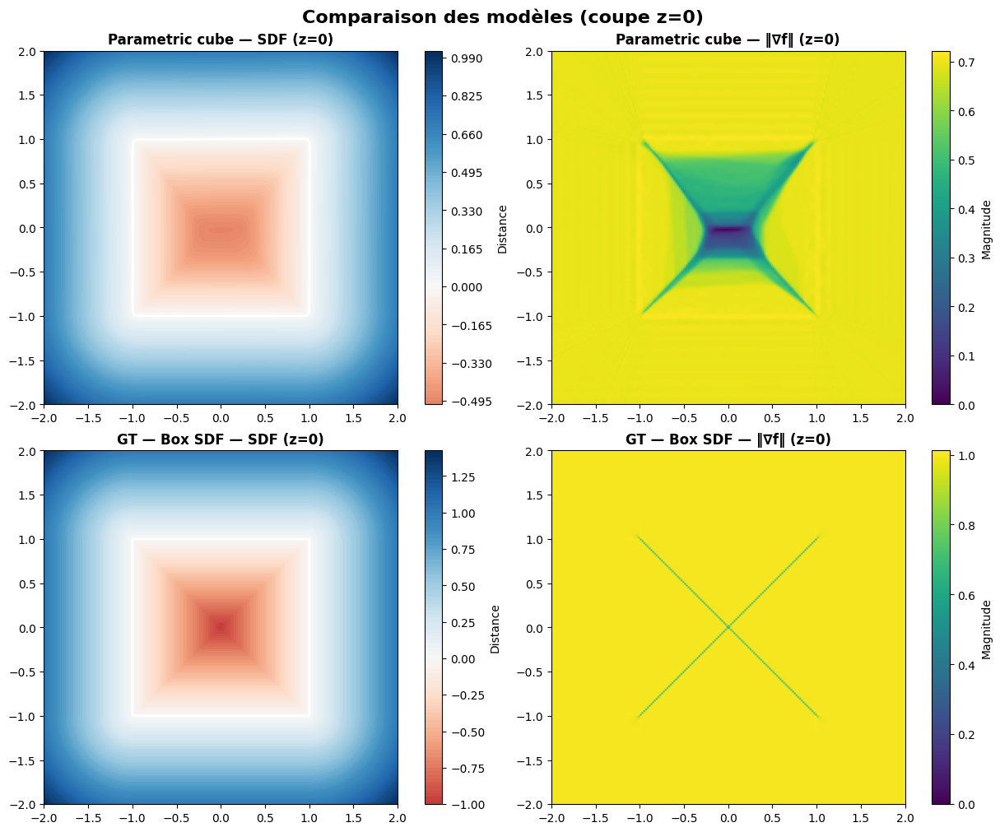

In [31]:
device = "cuda:0"

visualize_comparison(models=[(cube_model_param,"Parametric cube")], sdf_funcs=[(lambda p: box_sdf(p, b), "Box SDF") ], grid_res=200)
verts_param,faces_param = visualize_zero_set(cube_model_param, domain=[-2, 2], resolution=64, device=device)

In [24]:
model_param = cube_model_param.module

model_param.eval()

probe = torch.rand(4000, 3, device=device) * 4 - 2 
with torch.no_grad():
    near_surface = probe[cube_model_param(probe).reshape(-1).abs() < 0.1][:200]
h_min = calibrate_h_min(cube_model_param, near_surface)
print(h_min)

0.02


In [25]:
leaves_param = compute_octree(
    model_param,
    domain=(-2, 2),
    max_depth=6,
    min_depth=1,
    curvature_threshold=1.2, 
    device='cuda:0',
    fd = True,
    hmin = h_min
)
print(f"{len(leaves_param)} feuilles générées")
plot_octree(leaves_param)


Depth 0: center=[0.0, 0.0, 0.0], half=2.0, curvature=21.74041
Depth 1: center=[-1.0, -1.0, -1.0], half=1.0, curvature=10.35820
Depth 2: center=[-1.5, -1.5, -1.5], half=0.5, curvature=1.95460
Depth 2: center=[-1.5, -1.5, -0.5], half=0.5, curvature=2.02903
Depth 2: center=[-1.5, -0.5, -1.5], half=0.5, curvature=0.62356
Depth 2: center=[-1.5, -0.5, -0.5], half=0.5, curvature=0.19308
Depth 2: center=[-0.5, -1.5, -1.5], half=0.5, curvature=3.07102
Depth 3: center=[-0.75, -1.75, -1.75], half=0.25, curvature=2.67461
Depth 3: center=[-0.75, -1.75, -1.25], half=0.25, curvature=2.64596
Depth 3: center=[-0.75, -1.25, -1.75], half=0.25, curvature=0.06130
Depth 3: center=[-0.75, -1.25, -1.25], half=0.25, curvature=6.11794
Depth 4: center=[-0.875, -1.375, -1.375], half=0.125, curvature=5.03456
Depth 4: center=[-0.875, -1.375, -1.125], half=0.125, curvature=0.38175
Depth 4: center=[-0.875, -1.125, -1.375], half=0.125, curvature=2.62781
Depth 4: center=[-0.875, -1.125, -1.125], half=0.125, curvature=7

In [26]:
# param
balanced_leaves_param = balance_octree(leaves_param, domain=(-2, 2), max_passes=10)

In [27]:
verts_dc_param, faces_dc_param = dual_contouring(model_param, balanced_leaves_param, device=device, newton_iters=3)

In [28]:
plot_mesh(verts_dc_param, faces_dc_param)
plot_mesh_wireframe(verts_dc_param,faces_dc_param)
plot_curvature_on_mesh(model_param,verts_dc_param,faces_dc_param,h_min)

longueur des aretes : min=0.0029 max=0.7072 p50=0.0999 p95=0.2502


courbure aux sommets : min=0.000 max=43.963 p50=0.467 p95=23.710
